# Introduction

Bike sharing systems are a means of renting bicycles where the process of obtaining membership, rental, and bike return is automated via a network of kiosk locations throughout a city. Using these systems, people can rent a bike from one location and return it to a different place on an as-needed basis. 

This dataset contains valuable information about bike rentals, including various features such as datetime, weather conditions, and holidays. The dataset provided hourly rental data spanning two years. For this competition, the training set is comprised of the first 19 days of each month, while the test set is from the 20th to the end of the month.

By harnessing the power of regression algorithms, this project aims to predict the total count of bikes rented during each hour covered by the test set, based on only information available before the rental period. By evaluating the performance of different regression models using the Root Mean Squared Logarithmic Error (RMSLE), we will select the most accurate model that best captures the underlying relationships within the data.

Ultimately, the goal of this project is to not only develop a reliable prediction model but also through a comprehensive analysis of the dataset, this project seeks to unearth meaningful insights about the factors influencing bike rentals. These insights could potentially aid stakeholders in making informed decisions to optimize bike availability, marketing strategies, and resource allocation.

### Understanding the Variables

1. datetime: hourly date + timestamp  
Clear, Few clouds, Partly cloudy, Partly cloudy

2. season:    
           1 = spring   
           2 = summer
           3 = fall
           4 = winter
           
           
3. holiday: whether the day is considered a holiday, 
             1 = holiday 
             0 = not holiday
            

4. workingday: whether the day is neither a weekend nor holiday
                1 = working day 
                0 = not working day
               

5. weather: 
            1 = Clear, Few clouds, Partly cloudy, Partly cloudy
            2 = Mist + Cloudy, Mist + Broken clouds, Mist + Few clouds, Mist
            3 = Light Snow, Light Rain + Thunderstorm + Scattered clouds, Light Rain + Scattered clouds
            4 = Heavy Rain + Ice Pallets + Thunderstorm + Mist, Snow + Fog 
            
            
6. temp: temperature in Celsius

7. atemp: "feels like" temperature in Celsius

8. humidity: relative humidity

9. windspeed: wind speed

10. casual: number of non-registered user rentals initiated

11. registered: number of registered user rentals initiated

12. count: number of total rentals

In [1]:
# Import libraries. begin, let's import the necessary libraries that we'll be using throughout this notebook:

# Data Manipulation Libraries
import numpy as np 
import pandas as pd 

# Data Visualization Libraries
import seaborn as sns
import matplotlib.pyplot as plt

# Machine Learning Libraries
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.metrics import mean_squared_log_error, make_scorer

# Machine Learning Models
from sklearn.linear_model import LinearRegression  
from sklearn.tree import DecisionTreeRegressor  
from sklearn.ensemble import RandomForestRegressor

/opt/conda/lib/python3.10/site-packages/scipy/__init__.py:146: UserWarning: A NumPy version >=1.16.5 and <1.23.0 is required for this version of SciPy (detected version 1.23.5
  warnings.warn(f"A NumPy version >={np_minversion} and <{np_maxversion}"


In [2]:
# knowing the name of the dataset.
import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

/kaggle/input/bike-sharing-demand/sampleSubmission.csv
/kaggle/input/bike-sharing-demand/train.csv
/kaggle/input/bike-sharing-demand/test.csv


In [3]:
# Load tha train data.
train = pd.read_csv("/kaggle/input/bike-sharing-demand/train.csv")
train.head()

,datetime,season,holiday,workingday,weather,temp,atemp,humidity,windspeed,casual,registered,count
0,2011-01-01 00:00:00,1,0,0,1,9.84,14.395,81,0.0,3,13,16
1,2011-01-01 01:00:00,1,0,0,1,9.02,13.635,80,0.0,8,32,40
2,2011-01-01 02:00:00,1,0,0,1,9.02,13.635,80,0.0,5,27,32
3,2011-01-01 03:00:00,1,0,0,1,9.84,14.395,75,0.0,3,10,13
4,2011-01-01 04:00:00,1,0,0,1,9.84,14.395,75,0.0,0,1,1


In [4]:
# Load tha test data.
test = pd.read_csv("/kaggle/input/bike-sharing-demand/test.csv")
test.head()

,datetime,season,holiday,workingday,weather,temp,atemp,humidity,windspeed
0,2011-01-20 00:00:00,1,0,1,1,10.66,11.365,56,26.0027
1,2011-01-20 01:00:00,1,0,1,1,10.66,13.635,56,0.0000
2,2011-01-20 02:00:00,1,0,1,1,10.66,13.635,56,0.0000
3,2011-01-20 03:00:00,1,0,1,1,10.66,12.880,56,11.0014
4,2011-01-20 04:00:00,1,0,1,1,10.66,12.880,56,11.0014


# preparation the train data

In [5]:
# Seeing the shape of the data.
train.shape

(10886, 12)

In [6]:
# Seeing if there are dublicated.
train.duplicated().sum()

0

In [7]:
# seeing if there are null values.
train.isna().sum()

datetime      0
season        0
holiday       0
workingday    0
weather       0
temp          0
atemp         0
humidity      0
windspeed     0
casual        0
registered    0
count         0
dtype: int64

In [8]:
# Seeing information about data.
train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10886 entries, 0 to 10885
Data columns (total 12 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   datetime    10886 non-null  object 
 1   season      10886 non-null  int64  
 2   holiday     10886 non-null  int64  
 3   workingday  10886 non-null  int64  
 4   weather     10886 non-null  int64  
 5   temp        10886 non-null  float64
 6   atemp       10886 non-null  float64
 7   humidity    10886 non-null  int64  
 8   windspeed   10886 non-null  float64
 9   casual      10886 non-null  int64  
 10  registered  10886 non-null  int64  
 11  count       10886 non-null  int64  
dtypes: float64(3), int64(8), object(1)
memory usage: 1020.7+ KB


To unlock a deeper level of analysis and facilitate insightful observations from the dataset, we will Convert the "datetime" variable from its current "object" type to a structured "datetime" format that enriches the dataset. This separation enables more precise temporal analysis, unveiling trends across months, days, and hours.

In [9]:
# Convert the 'datetime' column to datetime format
train['datetime'] = pd.to_datetime(train['datetime'])

In [10]:
# Seeing information about data.
train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10886 entries, 0 to 10885
Data columns (total 12 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   datetime    10886 non-null  datetime64[ns]
 1   season      10886 non-null  int64         
 2   holiday     10886 non-null  int64         
 3   workingday  10886 non-null  int64         
 4   weather     10886 non-null  int64         
 5   temp        10886 non-null  float64       
 6   atemp       10886 non-null  float64       
 7   humidity    10886 non-null  int64         
 8   windspeed   10886 non-null  float64       
 9   casual      10886 non-null  int64         
 10  registered  10886 non-null  int64         
 11  count       10886 non-null  int64         
dtypes: datetime64[ns](1), float64(3), int64(8)
memory usage: 1020.7 KB


In [11]:
# Extract the year from the 'datetime' column and create a new 'year' column
train['year'] = train['datetime'].dt.year

# Extract the month as its name from the 'datetime' column and create a new 'month' column
train['month'] = train['datetime'].dt.month_name()

# Extract the day as its name from the 'datetime' column and create a new 'day' column
train['day'] = train['datetime'].dt.day_name()

# Extract the hour from the 'datetime' column and create a new 'hour' column
train['hour'] = train['datetime'].dt.hour

train.head()

,datetime,season,holiday,workingday,weather,temp,atemp,humidity,windspeed,casual,registered,count,year,month,day,hour
0,2011-01-01 00:00:00,1,0,0,1,9.84,14.395,81,0.0,3,13,16,2011,January,Saturday,0
1,2011-01-01 01:00:00,1,0,0,1,9.02,13.635,80,0.0,8,32,40,2011,January,Saturday,1
2,2011-01-01 02:00:00,1,0,0,1,9.02,13.635,80,0.0,5,27,32,2011,January,Saturday,2
3,2011-01-01 03:00:00,1,0,0,1,9.84,14.395,75,0.0,3,10,13,2011,January,Saturday,3
4,2011-01-01 04:00:00,1,0,0,1,9.84,14.395,75,0.0,0,1,1,2011,January,Saturday,4


In order to further dissect and comprehend the dataset, the datetime variable has been meticulously segmented. This segmentation involves extracting distinct temporal components, namely the year, month, day, and hour, from the datetime column. The result is a more structured representation of time-related data that facilitates seamless analysis and visualization and understanding of bike rental patterns.

In [12]:
# Replace the values in the 'season' column with corresponding strings
train['season'].replace({1: 'Spring', 2: 'Summer', 3: 'Fall', 4: 'Winter'}, inplace=True)

# Replace the values in the 'holiday' column with corresponding strings
train['holiday'].replace({1: 'Holiday', 0: 'Not Holiday'}, inplace=True)

# Replace the values in the 'workingday' column with corresponding strings
train['workingday'].replace({1: 'Workingday', 0: 'Not Workingday'}, inplace=True)

# Replace the values in the 'weather' column with corresponding strings
train['weather'].replace({1: 'Clear', 2: 'Mist', 3: 'Rain', 4: 'Snow'}, inplace=True)

train.head()

,datetime,season,holiday,workingday,weather,temp,atemp,humidity,windspeed,casual,registered,count,year,month,day,hour
0,2011-01-01 00:00:00,Spring,Not Holiday,Not Workingday,Clear,9.84,14.395,81,0.0,3,13,16,2011,January,Saturday,0
1,2011-01-01 01:00:00,Spring,Not Holiday,Not Workingday,Clear,9.02,13.635,80,0.0,8,32,40,2011,January,Saturday,1
2,2011-01-01 02:00:00,Spring,Not Holiday,Not Workingday,Clear,9.02,13.635,80,0.0,5,27,32,2011,January,Saturday,2
3,2011-01-01 03:00:00,Spring,Not Holiday,Not Workingday,Clear,9.84,14.395,75,0.0,3,10,13,2011,January,Saturday,3
4,2011-01-01 04:00:00,Spring,Not Holiday,Not Workingday,Clear,9.84,14.395,75,0.0,0,1,1,2011,January,Saturday,4


To improve data clarity and interpretation we replaced numerical values in certain columns with corresponding descriptive strings. This process facilitates a more intuitive understanding of the dataset's categorical attributes and makes it more accessible for analysis and interpretation.

In [13]:
# Categorical columns.
categorical_features = train[['season', 'holiday', 'workingday', 'weather',  'year', 'month', 'day', 'hour']]

for i in categorical_features:
    print(train[i].value_counts())
    print('-' * 50)

Winter    2734
Summer    2733
Fall      2733
Spring    2686
Name: season, dtype: int64
--------------------------------------------------
Not Holiday    10575
Holiday          311
Name: holiday, dtype: int64
--------------------------------------------------
Workingday        7412
Not Workingday    3474
Name: workingday, dtype: int64
--------------------------------------------------
Clear    7192
Mist     2834
Rain      859
Snow        1
Name: weather, dtype: int64
--------------------------------------------------
2012    5464
2011    5422
Name: year, dtype: int64
--------------------------------------------------
May          912
June         912
July         912
August       912
December     912
October      911
November     911
April        909
September    909
February     901
March        901
January      884
Name: month, dtype: int64
--------------------------------------------------
Saturday     1584
Sunday       1579
Thursday     1553
Monday       1551
Wednesday    1551
Tuesd

We've discerned two observations:

First, it is the presence of a single value for 'snow' which leads to a potentially negative impact on our analysis. To mitigate this, we chose to combine it with the category 'rain' within the same column.

Second, we realized that there was a discrepancy between the number of 'holiday' and 'not-workingday', and it was shown in the understanding of the variables that 'workingday' is the day that is neither a weekend nor a holiday. Furthermore, the dataset shows cases where neither 'workingday' nor 'holiday' applies. Thus, this underscores the need for a third variable: the 'weekend'. This variable summarizes scenarios where work or vacation are not active, effectively representing a 'weekend'. This subtle distinction makes clear that our reference to 'holiday' relates exclusively to public holidays, which are distinct from 'weekend' holidays.

In [14]:
# Define a mapping dictionary to combine the clusters
cluster_mapping = {"Snow" : "Rain"}

# Update the "grade" column with the new cluster labels
train['weather'] = train['weather'].replace(cluster_mapping)

# Check the value_counts for the weather after replacing
train['weather'].value_counts()

Clear    7192
Mist     2834
Rain      860
Name: weather, dtype: int64

In [15]:
# Filter rows where 'workingday' is equal to 'Workingday'
workingDay = train[train['workingday'] == 'Workingday']

# Filter rows where 'holiday' is equal to 'Holiday'
holiDay = train[train['holiday'] == 'Holiday']

# Filter rows where 'holiday' is not 'Holiday' and 'workingday' is not 'Workingday'
weekEnd = train[(train['holiday'] == 'Not Holiday') & (train['workingday'] == 'Not Workingday')]

In [16]:
# Numerical columns.
numerical_features = train[['temp', 'atemp', 'humidity', 'windspeed', 'casual', 'registered', 'count']]

# calculate descriptive statistics for numerical values.
numerical_features.describe()

,temp,atemp,humidity,windspeed,casual,registered,count
count,10886.00000,10886.000000,10886.000000,10886.000000,10886.000000,10886.000000,10886.000000
mean,20.23086,23.655084,61.886460,12.799395,36.021955,155.552177,191.574132
std,7.79159,8.474601,19.245033,8.164537,49.960477,151.039033,181.144454
min,0.82000,0.760000,0.000000,0.000000,0.000000,0.000000,1.000000
25%,13.94000,16.665000,47.000000,7.001500,4.000000,36.000000,42.000000
50%,20.50000,24.240000,62.000000,12.998000,17.000000,118.000000,145.000000
75%,26.24000,31.060000,77.000000,16.997900,49.000000,222.000000,284.000000
max,41.00000,45.455000,100.000000,56.996900,367.000000,886.000000,977.000000


We have identified an issue with wind speed and humidity variables having a minimum value of zero, which is inherently illogical for wind speed or humidity to be zero. As a solution, we will replace these zeros with more reasonable values to ensure data consistency and reliability.

In [17]:
# Get the count of the minimum value
count_of_min_value = train[train['humidity']==0].shape[0]

count_of_min_value

22

In [18]:
# Filter rows with the minimum value
min_value_rows = train[train['humidity'] == 0]

min_value_rows

,datetime,season,holiday,workingday,weather,temp,atemp,humidity,windspeed,casual,registered,count,year,month,day,hour
1091,2011-03-10 00:00:00,Spring,Not Holiday,Workingday,Rain,13.94,15.910,0,16.9979,3,0,3,2011,March,Thursday,0
1092,2011-03-10 01:00:00,Spring,Not Holiday,Workingday,Rain,13.94,15.910,0,16.9979,0,2,2,2011,March,Thursday,1
1093,2011-03-10 02:00:00,Spring,Not Holiday,Workingday,Rain,13.94,15.910,0,16.9979,0,1,1,2011,March,Thursday,2
1094,2011-03-10 05:00:00,Spring,Not Holiday,Workingday,Rain,14.76,17.425,0,12.9980,1,2,3,2011,March,Thursday,5
1095,2011-03-10 06:00:00,Spring,Not Holiday,Workingday,Rain,14.76,16.665,0,22.0028,0,12,12,2011,March,Thursday,6
1096,2011-03-10 07:00:00,Spring,Not Holiday,Workingday,Rain,15.58,19.695,0,15.0013,1,36,37,2011,March,Thursday,7
1097,2011-03-10 08:00:00,Spring,Not Holiday,Workingday,Rain,15.58,19.695,0,19.0012,1,43,44,2011,March,Thursday,8
1098,2011-03-10 09:00:00,Spring,Not Holiday,Workingday,Rain,16.40,20.455,0,15.0013,1,23,24,2011,March,Thursday,9
1099,2011-03-10 10:00:00,Spring,Not Holiday,Workingday,Rain,16.40,20.455,0,11.0014,0,17,17,2011,March,Thursday,10
1100,2011-03-10 11:00:00,Spring,Not Holiday,Workingday,Rain,16.40,20.455,0,16.9979,6,5,11,2011,March,Thursday,11


In [19]:
# Filter rows where the weather is 'Rain'
rain_weather = train[train['weather'] == 'Rain']

# Calculate the mean humidity for rows with 'Rain' weather
mean_rain_weather_humidity = rain_weather['humidity'].mean()

# Replace 0 values in the 'humidity' column with the calculated mean for 'Rain' weather
train['humidity'] = train['humidity'].replace(0, mean_rain_weather_humidity)

# Check the minimum value in the 'humidity' column after replacing 0 values
train['humidity'].min()

8.0

We found 22 instances of zero humidity readings, 
Intriguingly, these instances are all recorded on the same day. This suggests a potential recording error for that day's humidity data. 

To address this, we filled these instances with an appropriate value. Given that the day was mostly rainy, we calculated an average humidity value for rainy conditions in the dataset and used it to replace the zeros. This approach ensures data consistency and accuracy despite the recording irregularity.

In [20]:
# Get the count of the minimum value
count_of_min_value = train[train['windspeed']==0].shape[0]

count_of_min_value

1313

In [21]:
# Filter rows with the minimum value
min_value_rows = train[train['windspeed'] == 0]

min_value_rows.sample(10)

,datetime,season,holiday,workingday,weather,temp,atemp,humidity,windspeed,casual,registered,count,year,month,day,hour
4628,2011-11-05 22:00:00,Winter,Not Holiday,Not Workingday,Clear,12.30,16.665,65.0,0.0,10,72,82,2011,November,Saturday,22
4213,2011-10-07 14:00:00,Winter,Not Holiday,Workingday,Clear,25.42,31.060,50.0,0.0,77,179,256,2011,October,Friday,14
8,2011-01-01 08:00:00,Spring,Not Holiday,Not Workingday,Clear,9.84,14.395,75.0,0.0,1,7,8,2011,January,Saturday,8
4355,2011-10-13 12:00:00,Winter,Not Holiday,Workingday,Mist,25.42,28.030,88.0,0.0,10,95,105,2011,October,Thursday,12
3817,2011-09-10 01:00:00,Fall,Not Holiday,Not Workingday,Mist,25.42,27.275,94.0,0.0,16,67,83,2011,September,Saturday,1
9267,2012-09-09 12:00:00,Fall,Not Holiday,Not Workingday,Clear,27.06,31.060,47.0,0.0,247,510,757,2012,September,Sunday,12
597,2011-02-08 01:00:00,Spring,Not Holiday,Workingday,Mist,11.48,15.910,87.0,0.0,0,4,4,2011,February,Tuesday,1
8600,2012-07-19 17:00:00,Fall,Not Holiday,Workingday,Clear,35.26,39.395,41.0,0.0,93,678,771,2012,July,Thursday,17
6808,2012-04-01 23:00:00,Summer,Not Holiday,Not Workingday,Rain,18.86,22.725,72.0,0.0,10,53,63,2012,April,Sunday,23
5288,2011-12-14 10:00:00,Winter,Not Holiday,Workingday,Mist,13.12,17.425,57.0,0.0,9,133,142,2011,December,Wednesday,10


In [22]:
# Replace zero 'windspeed with the values above or below
train['windspeed'] = train['windspeed'].replace(0, method='ffill').replace(0, method='bfill')

# Check the minimum value in the 'windspeed' column after replacing 0 values
train['windspeed'].min()

6.0032

We've noticed a total of 1313 instances with zero wind speed values scattered throughout the dataset. 

To address this, we're opting to replace these zero values with their adjacent non-zero counterparts. This adjustment aims to approximate more realistic values by maintaining the trend found in the data.

# Data Visualiation and Analysis

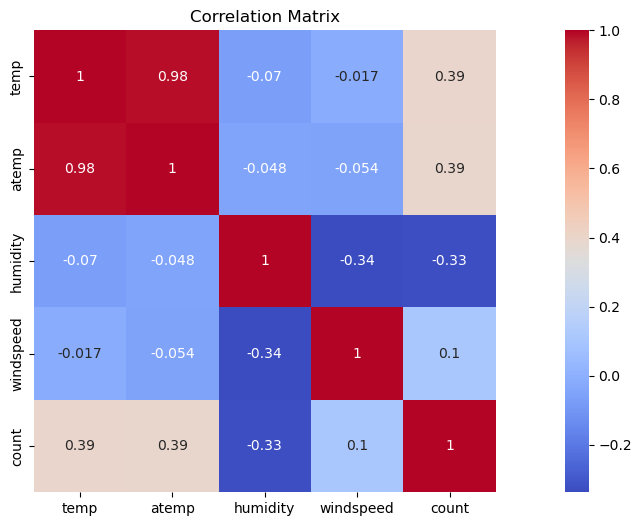

In [23]:
# Calculate the correlation matrix for the selected numerical features in the 'data' DataFrame.
correlation_matrix = train[['temp', 'atemp', 'humidity', 'windspeed', 'count']].corr()

# Plot the correlation matrix as a heatmap
plt.figure(figsize=(18, 6))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', square=True)
plt.title('Correlation Matrix')
plt.show()


As we have seen in the above graph,

1- There is a high correlation between the 'temp' column and the 'atemp' column, so we remove one of them because the two feature act as one feature

2- There is a week positive correlation between the 'temp' column and the target 'count' (0.39), a week negative correlation between the 'humidity' column and the target (-0.32), but there is no correlation between windspeed and the target (0.1).

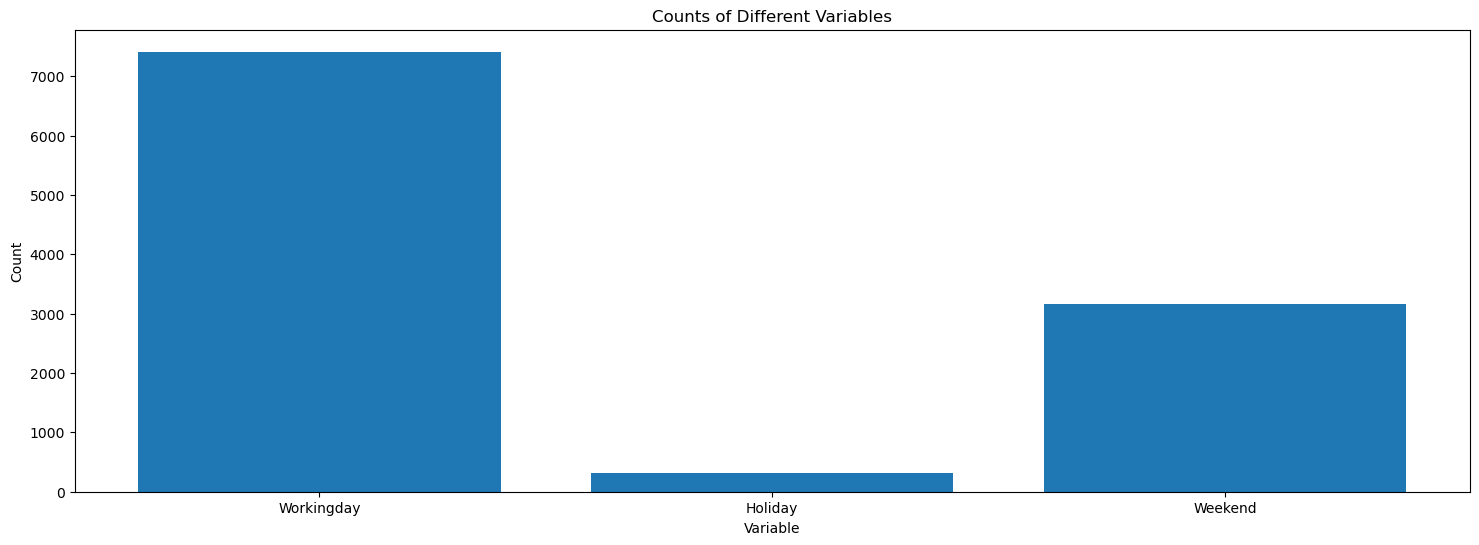

In [24]:
# Calculate counts
counts = [workingDay.shape[0], holiDay.shape[0], weekEnd.shape[0]]
labels = ['Workingday', 'Holiday', 'Weekend']

# Create a bar chart
plt.figure(figsize=(18, 6))
plt.bar(labels, counts)
plt.xlabel('Variable')
plt.ylabel('Count')
plt.title('Counts of Different Variables')
plt.show()

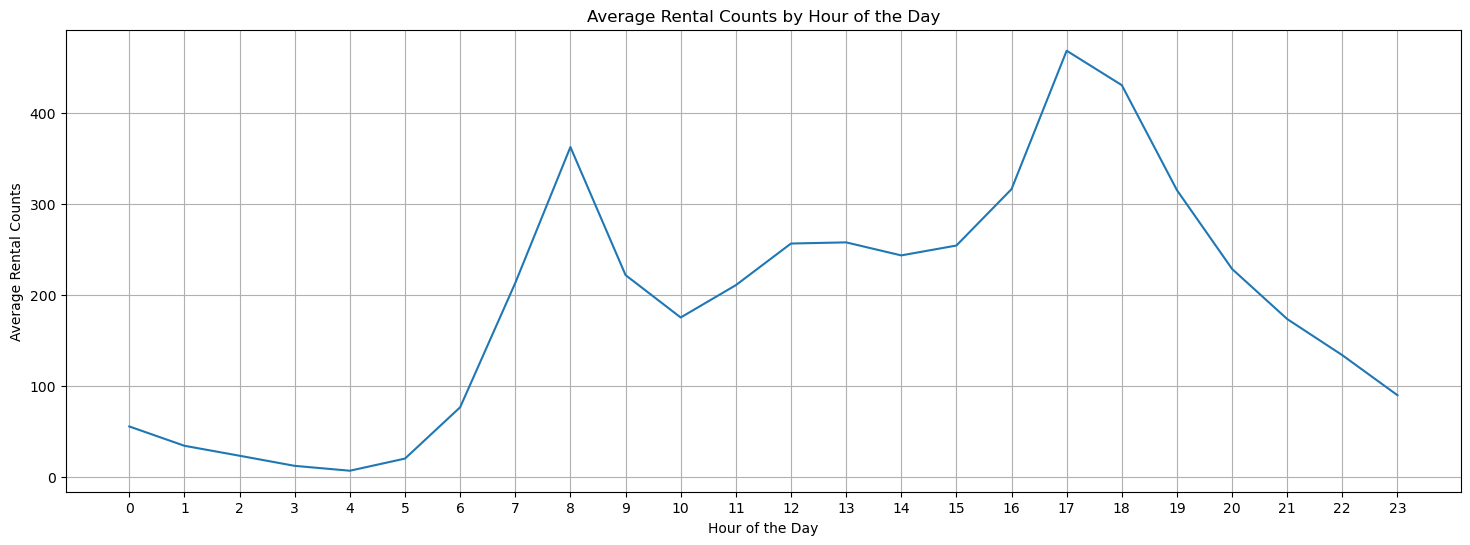

In [25]:
# Calculate the average rental counts by hour of the day
hourly_counts = train.groupby('hour')['count'].mean().reset_index()

# Create a line plot to visualize the average rental counts by hour
plt.figure(figsize=(18, 6))
sns.lineplot(x='hour', y='count', data=hourly_counts)
plt.xlabel('Hour of the Day')
plt.ylabel('Average Rental Counts')
plt.title('Average Rental Counts by Hour of the Day')
plt.xticks(ticks=range(24), labels=range(24))
plt.grid()
plt.show()

Text(0, 0.5, 'Mean Count')

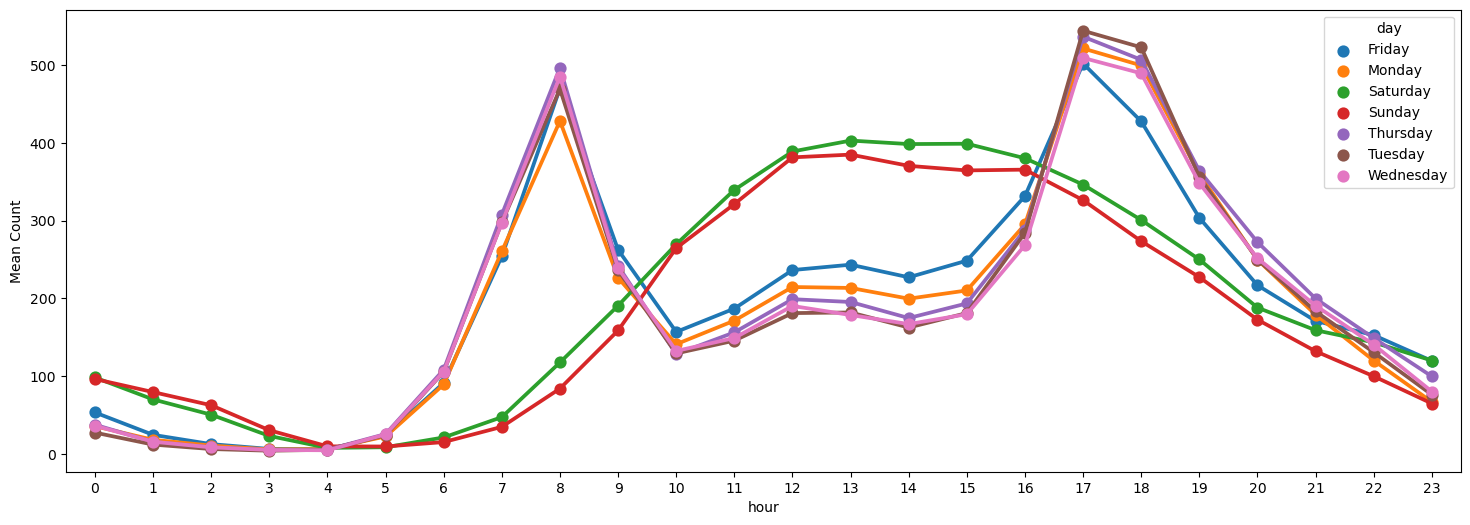

In [26]:
# Plot the mean rental counts per hour based on day of the week
plt.figure(figsize=(18, 6))
hour_day_df = train.groupby(["hour", "day"])["count"].mean().to_frame().reset_index()
ax1 = sns.pointplot(x=hour_day_df["hour"], y=hour_day_df["count"], hue=hour_day_df["day"])
ax1.set_ylabel("Mean Count")

In [27]:
# Extracting unique days from the 'day' column of the 'weekEnd' DataFrame
weekEnd['day'].unique()

array(['Saturday', 'Sunday'], dtype=object)

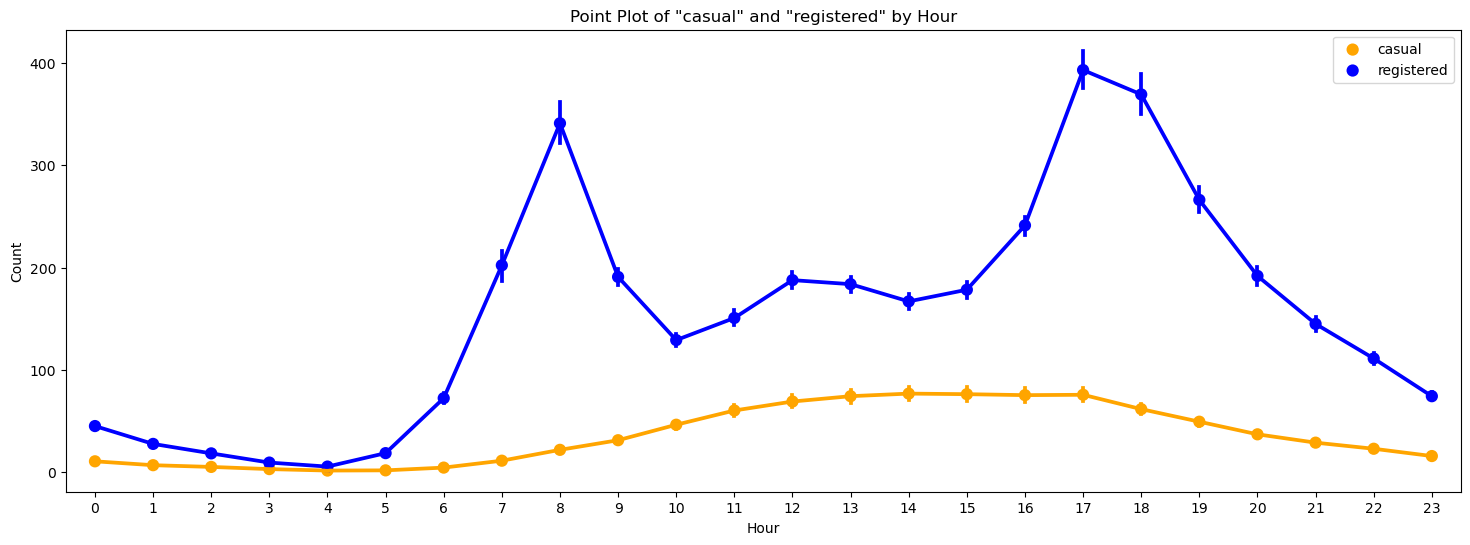

In [28]:
# Set up the plot
plt.figure(figsize=(18, 6))

# Create a point plot for 'casual' and 'registered' by 'hour'
sns.pointplot(data=train, x='hour', y='casual', color='orange', label='casual')
sns.pointplot(data=train, x='hour', y='registered', color='blue', label='registered')

plt.title('Point Plot of "casual" and "registered" by Hour')
plt.xlabel('Hour')
plt.ylabel('Count')
plt.legend()

plt.show()


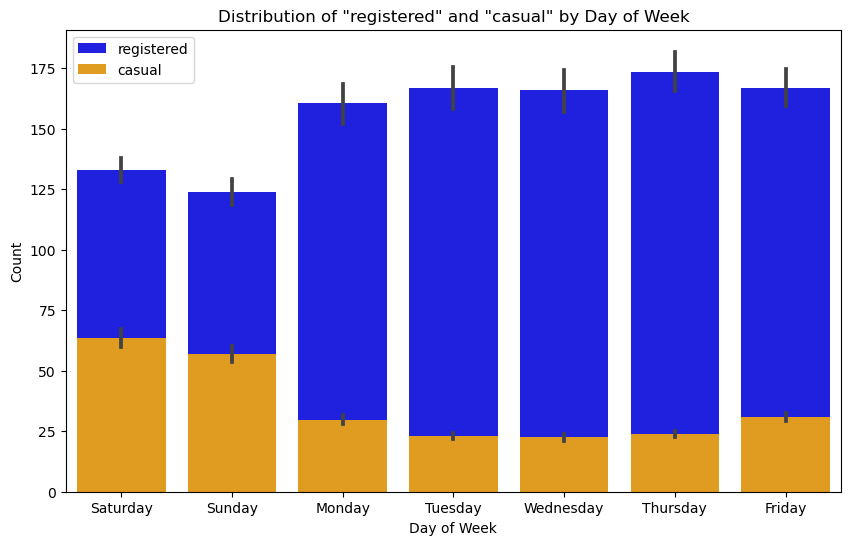

In [29]:
# Set up the plot
plt.figure(figsize=(10, 6))

# Create a bar plot to visualize distribution of 'registered' and 'casual' by 'day'
sns.barplot(data=train, x='day', y='registered', color='blue', label='registered')
sns.barplot(data=train, x='day', y='casual', color='orange', label='casual')

plt.title('Distribution of "registered" and "casual" by Day of Week')
plt.xlabel('Day of Week')
plt.ylabel('Count')
plt.legend()

plt.show()


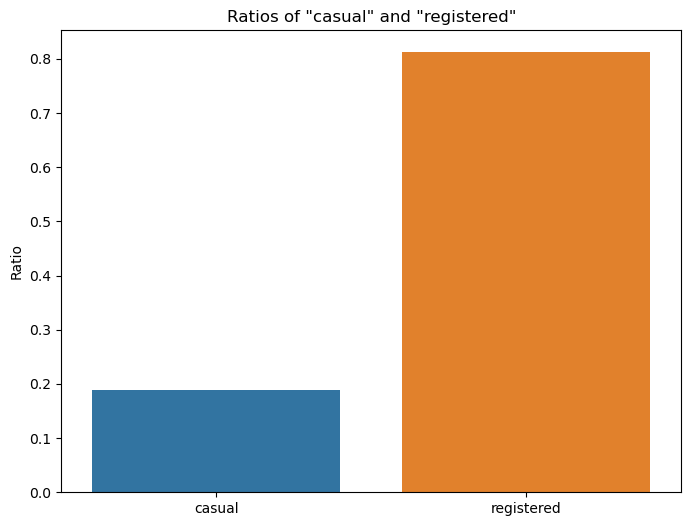

In [30]:
# Calculate the total counts for 'casual' and 'registered'
total_casual = train['casual'].sum()
total_registered = train['registered'].sum()

# Calculate the ratios
ratio_casual = total_casual / (total_casual + total_registered)
ratio_registered = total_registered / (total_casual + total_registered)

# Create a bar plot for the ratios of 'casual' and 'registered'
ratios = [ratio_casual, ratio_registered]
labels = ['casual', 'registered']

plt.figure(figsize=(8, 6))
sns.barplot(x=labels, y=ratios)
plt.title('Ratios of "casual" and "registered"')
plt.ylabel('Ratio')
plt.show()

From the preceding graphs, a clear pattern emerges: workdays witness the highest bike rental frequency, followed by weekends, and subsequently, official holidays. Notably, the peak hours for bike rentals consistently appear at 7 AM and 5 PM on all days except Saturday and Sunday. During weekends, a shift is apparent, with rental surges occurring from 11 AM to 5 PM.

Furthermore, the data underscores that registered users predominantly utilize bikes during workdays, evident in their peak usage hours at 7 AM and 5 PM. In contrast, casual users, often utilizing bikes for leisure, exhibit pronounced activity during weekends. Consequently, weekends witness a different usage pattern compared to workdays. It's noteworthy that weekend rentals overall tend to be less frequent, accompanied by a higher proportion of casual users.

Interestingly, the dataset features a larger count of registered users compared to casual users. This insight reinforces the prevalence of consistent bike usage patterns among registered users, primarily on workdays, in contrast to the more varied casual usage on weekends.

In summary, the analysis unveils a notable interplay between user types, work schedules, and rental peak hours, enhancing our understanding of the dynamics behind bike rentals.

Text(0, 0.5, 'Mean Count')

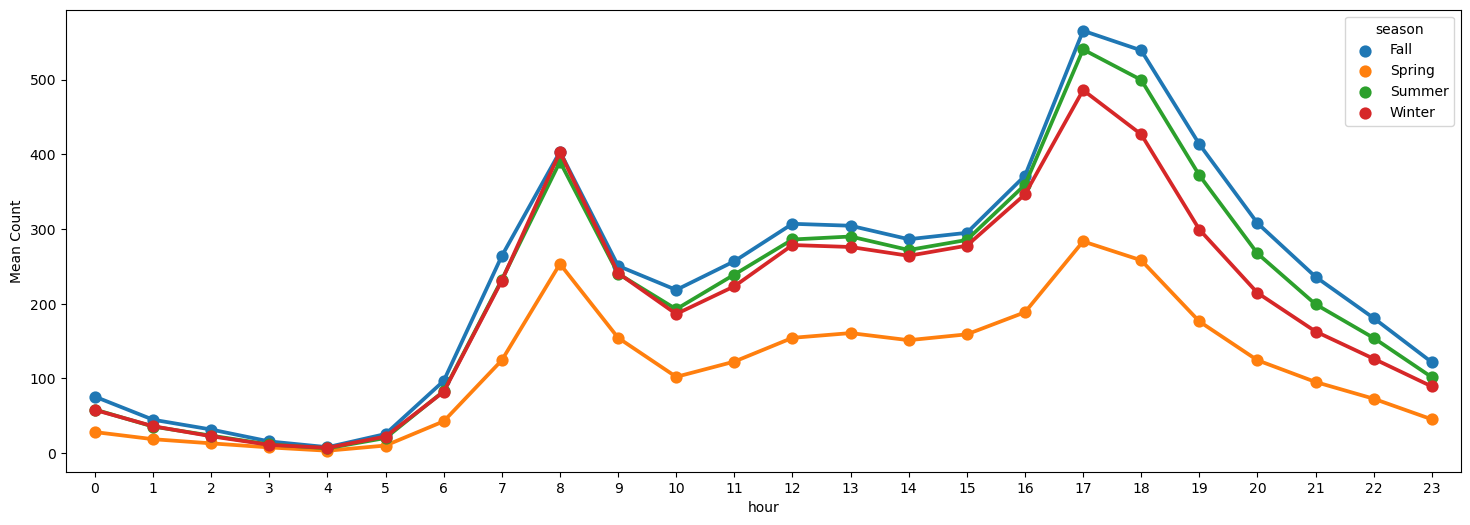

In [31]:
# Plot the mean rental counts per hour based on season
plt.figure(figsize=(18, 6))
hour_season_df = train.groupby(["hour", "season"])["count"].mean().to_frame().reset_index()
ax2 = sns.pointplot(x=hour_season_df["hour"], y=hour_season_df["count"], hue=hour_season_df["season"])
ax2.set_ylabel("Mean Count")


It's evident that peak hours for bike rentals remain consistent across seasons, likely due to work-related commuting patterns that persist regardless of the time of year. 

Interestingly, despite the consistent peak hour trend, spring stands out with lower bike rental counts. This divergence could be attributed to the prevalence of official holidays during the spring months.

In [32]:
# Count the occurrences of each season in the 'season' column of the 'holiDay' DataFrame
holiDay['season'].value_counts()

Fall      96
Winter    96
Spring    71
Summer    48
Name: season, dtype: int64

The code indicates that the prevalence of official holidays is not significantly higher in the spring season, suggesting it might not be the main driver behind the decline in bike rentals during that period. 

In the context of spring, an alternative reason for the reduction could potentially stem from weather conditions. In the heat map analysis, we observed that bike rental counts exhibit a minor negative correlation with humidity and a positive correlation with temperature. This insight reinforces the notion that weather conditions could be contributing to diminished rental activity during the spring season.

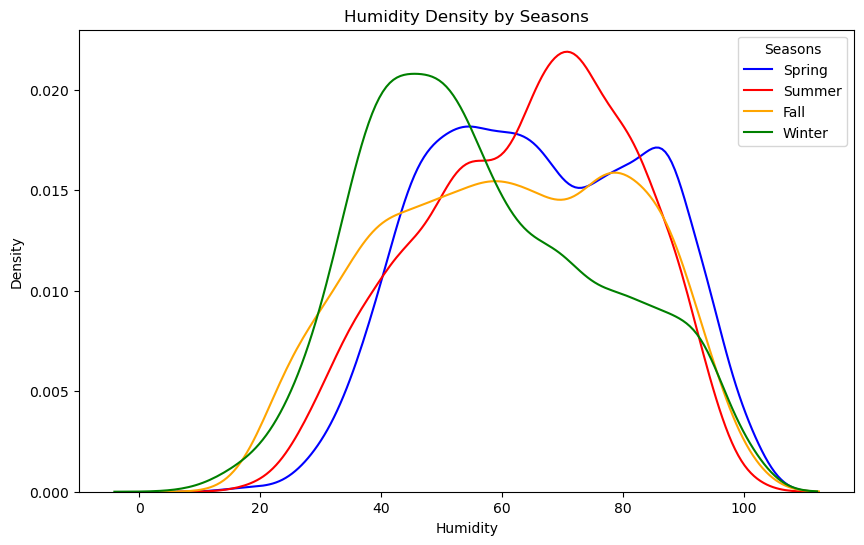

In [33]:
# Define custom colors for each season
season_colors = {
    'Spring': 'green',
    'Summer': 'orange',
    'Fall': 'red',
    'Winter': 'blue'
}

# Set up the plot
plt.figure(figsize=(10, 6))

# Create a kernel density plot of humidity by season with custom colors
sns.kdeplot(data=train, x='humidity', hue='season', common_norm=False, palette=season_colors.values())
plt.title('Humidity Density by Seasons')
plt.xlabel('Humidity')
plt.ylabel('Density')
plt.legend(title='Seasons', labels=season_colors.keys())

plt.show()

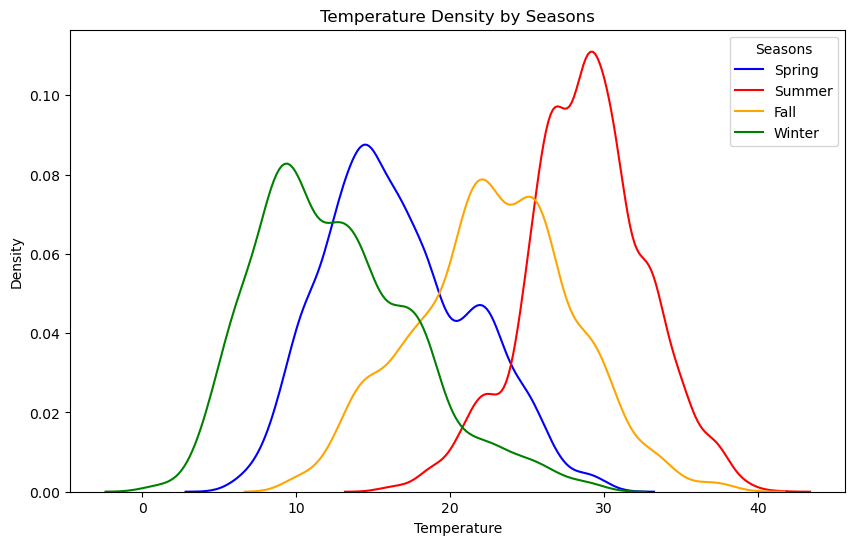

In [34]:
# Define custom colors for each season
season_colors = {
    'Spring': 'green',
    'Summer': 'orange',
    'Fall': 'red',
    'Winter': 'blue'
}

# Set up the plot
plt.figure(figsize=(10, 6))

# Create a kernel density plot of temperature by season with custom colors
sns.kdeplot(data=train, x='temp', hue='season', common_norm=False, palette=season_colors.values())
plt.title('Temperature Density by Seasons')
plt.xlabel('Temperature')
plt.ylabel('Density')
plt.legend(title='Seasons', labels=season_colors.keys())

plt.show()

The graphs clearly show that humidity levels during spring are not appreciably high to significantly reduce bike rentals. Furthermore, temperatures are not too low to affect the number of rentals. In fact, during summer, both humidity and temperature are Significantly higher, this did not affect bicycle rentals. Likewise, the remaining seasons show similar levels of humidity and temperature as spring, though only spring has the lowest number of bicycle fares.

This indicates that weather conditions, while a contributing factor, may not be the only driver of lower rents during the spring season. It is plausible that the distribution of the data could influence this outcome. Spring may have a relatively smaller data set compared to other seasons, which can lead to observed fluctuations in rental numbers.

In [35]:
# Calculate the number of days in each season
days_in_season = train['season'].value_counts().sort_index()

# Display the number of days in each season
print("Number of days in each season:")
print(days_in_season)

Number of days in each season:
Fall      2733
Spring    2686
Summer    2733
Winter    2734
Name: season, dtype: int64


<Axes: ylabel='season'>

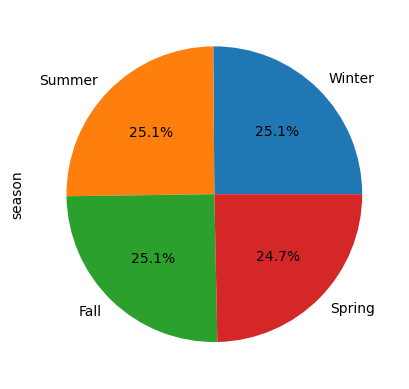

In [36]:
# Seeing the distribution of 'season' values in the train dataset
train['season'].value_counts().plot(kind = 'pie', autopct = '%1.1f%%')

The distribution of data appears remarkably balanced across seasons,  suggesting that it's unlikely the main reason for the lower rental counts in spring.

Consequently, there could be nuanced and less overt reasons within the dataset itself contributing to the reduction in rental counts during the spring season. These factors remain concealed, prompting a need for further exploration to uncover potential underlying causes responsible for this particular trend in the spring season.

# Data preprocessing

In [37]:
# Dropping unnecessary features that are not needed for modeling or have minimal impact
train.drop(['datetime', 'atemp', 'windspeed', 'casual', 'registered'], axis=1, inplace=True)

### Encoding and scalling the data

In [38]:
# One hot Endocing .
train = pd.get_dummies(train, columns=['season', 'weather', 'month', 'day'])

# Label Encoding.
label_encoder = LabelEncoder()

for i in ['holiday', 'workingday', 'year']:
    train[i] = label_encoder.fit_transform(train[i])

In [39]:
# List of columns to scale
columns_to_scale = ['temp', 'humidity', 'hour']

# Create a StandardScaler object
scaler = StandardScaler()

# Fit the StandardScaler on the selected columns to calculate mean and standard deviation
scaler.fit(train[columns_to_scale])

# Transform the selected columns using the calculated mean and standard deviation
train[columns_to_scale] = scaler.transform(train[columns_to_scale])


### Split the data

In [40]:
# Split data into x and y.
X = train.drop("count", axis=1)
y = train["count"]

# Split train data into train and test.
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Modeling

In [41]:
# Define the Root Mean Squared Logarithmic Error (RMSLE) scorer
def rmsle(y_true, y_pred):
    return np.sqrt(mean_squared_log_error(y_true, np.clip(y_pred, 0, None)))

# Make the RMSLE scorer
rmsle_scorer = make_scorer(rmsle)

The Root Mean Squared Logarithmic Error (RMSLE) scorer is utilized to assess the model's performance. RMSLE is a metric commonly used in regression tasks to measure the accuracy of predictions. It penalizes underestimation and overestimation of the target variable, making it suitable for this bike rental count prediction task. The lower the RMSLE value, the better the model's predictions align with the actual target values.

In [42]:
# Initialize and evaluate different regression models using cross-validation
models = {
    'Linear Regression': LinearRegression(),
    'Decision Tree': DecisionTreeRegressor(),
    'Random Forest': RandomForestRegressor()
}

In [43]:
# Iterate over each model and Perform cross-validation with RMSLE scorer
for model_name, model in models.items():
    cv_scores = cross_val_score(model, X_train, y_train, scoring=rmsle_scorer, cv=5)
    
    print(f"Model: {model_name}")
    print(f"Average RMSLE: {np.mean(cv_scores)}\n")

Model: Linear Regression
Average RMSLE: 1.2981041544137404

Model: Decision Tree
Average RMSLE: 0.4291352487435294

Model: Random Forest
Average RMSLE: 0.3345494416408514



After evaluating multiple regression models, we found that the Random Forest algorithm demonstrated the best performance based on the RMSLE metric. Therefore, we selected the Random Forest model to make predictions on our test data. 

In [44]:
# Fit and evaluate the best model on the test set
the_model = RandomForestRegressor()  
the_model.fit(X_train, y_train)

y_pred = the_model.predict(X_test)
test_rmsle = rmsle(y_test, y_pred)
print(f"Test RMSLE for the best model: {test_rmsle}")

Test RMSLE for the best model: 0.32466987799985236


# Preperation the test data

In [45]:
# Seeing if there are dublicated.
test.duplicated().sum()

0

In [46]:
# seeing if there are null values.
test.isna().sum()

datetime      0
season        0
holiday       0
workingday    0
weather       0
temp          0
atemp         0
humidity      0
windspeed     0
dtype: int64

In [47]:
test.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6493 entries, 0 to 6492
Data columns (total 9 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   datetime    6493 non-null   object 
 1   season      6493 non-null   int64  
 2   holiday     6493 non-null   int64  
 3   workingday  6493 non-null   int64  
 4   weather     6493 non-null   int64  
 5   temp        6493 non-null   float64
 6   atemp       6493 non-null   float64
 7   humidity    6493 non-null   int64  
 8   windspeed   6493 non-null   float64
dtypes: float64(3), int64(5), object(1)
memory usage: 456.7+ KB


In [48]:
# Convert the 'datetime' column to datetime format
test['datetime'] = pd.to_datetime(test['datetime'])

# Extract the year from the 'datetime' column and create a new 'year' column
test['year'] = test['datetime'].dt.year

# Extract the month as its name from the 'datetime' column and create a new 'month' column
test['month'] = test['datetime'].dt.month_name()

# Extract the day as its name from the 'datetime' column and create a new 'day' column
test['day'] = test['datetime'].dt.day_name()

# Extract the hour from the 'datetime' column and create a new 'hour' column
test['hour'] = test['datetime'].dt.hour

In [49]:
# Replace the values in the 'season' column with corresponding strings
test['season'].replace({1: 'Spring', 2: 'Summer', 3: 'Fall', 4: 'Winter'}, inplace=True)

# Replace the values in the 'holiday' column with corresponding strings
test['holiday'].replace({1: 'Holiday', 0: 'Not Holiday'}, inplace=True)

# Replace the values in the 'workingday' column with corresponding strings
test['workingday'].replace({1: 'Workingday', 0: 'Not Workingday'}, inplace=True)

# Replace the values in the 'weather' column with corresponding strings
test['weather'].replace({1: 'Clear', 2: 'Mist', 3: 'Rain', 4: 'Snow'}, inplace=True)

In [50]:
# Define a mapping dictionary to combine the clusters
cluster_mapping = {"Snow" : "Rain"}

# Update the "grade" column with the new cluster labels
test['weather'] = test['weather'].replace(cluster_mapping)

In [51]:
# Numerical columns.
numerical_features = test[['temp', 'atemp', 'humidity', 'windspeed']]

# calculate descriptive statistics for numerical values.
numerical_features.describe()

,temp,atemp,humidity,windspeed
count,6493.000000,6493.000000,6493.000000,6493.000000
mean,20.620607,24.012865,64.125212,12.631157
std,8.059583,8.782741,19.293391,8.250151
min,0.820000,0.000000,16.000000,0.000000
25%,13.940000,16.665000,49.000000,7.001500
50%,21.320000,25.000000,65.000000,11.001400
75%,27.060000,31.060000,81.000000,16.997900
max,40.180000,50.000000,100.000000,55.998600


In [52]:
# Replace zero 'windspeed' with the values above or below
test['windspeed'] = test['windspeed'].replace(0, method='ffill').replace(0, method='bfill')

In [53]:
#Store the datetime column in a separate variable.
datetime = test['datetime']

In [54]:
test.drop(['datetime', 'atemp', 'windspeed'], axis=1, inplace=True)

In [55]:
# One hot Endocing .
test = pd.get_dummies(test, columns=['season', 'weather', 'month', 'day'])

# Label Encoding.
label_encoder = LabelEncoder()

for i in ['holiday', 'workingday', 'year']:
    test[i] = label_encoder.fit_transform(test[i])

In [56]:
# List of columns to scale
columns_to_scale = ['temp', 'humidity', 'hour']

# Create a StandardScaler object
scaler = StandardScaler()

# Fit the StandardScaler on the selected columns to calculate mean and standard deviation
scaler.fit(test[columns_to_scale])

# Transform the selected columns using the calculated mean and standard deviation
test[columns_to_scale] = scaler.transform(test[columns_to_scale])


# Prediction and Submissiom

In [57]:
# Generate predictions for the test data using RandomForestClassifier.
test_pred = the_model.predict(test)

In [58]:
# Create a submission DataFrame with the 'datetime' column and predicted rental counts.
submission = pd.DataFrame({'datetime': datetime, 'count': test_pred})


In [59]:
# Save the submission DataFrame as a CSV file without including the index column.
submission.to_csv('submission.csv', index=False)
print("Your submission was successfully saved!")

Your submission was successfully saved!


# Conclusion

Our journey of data preparation and analysis has yielded significant insights and successful model utilization. We embarked on a meticulous process of refining the dataset, including datetime format conversion, categorical value replacements, and addressing anomalies in variables like humidity and wind speed. This foundational work set the stage for more accurate analysis and model training.

Through exploratory data analysis, we unveiled crucial trends and patterns. Notably, we observed that weekdays outshine weekends and holidays in bike rental counts, and specific peak hours consistently attract more rentals.

Upon model evaluation, the Random Forest algorithm demonstrated remarkable prowess by achieving the lowest RMSLE score. 

To sum up, our journey encompassed data refinement, insightful analysis, meticulous model selection, and comprehensive utilization of predictions. This endeavor equips us with valuable information for strategic decision-making.